# RNN and LSTM Math: Theory Notebook

This notebook makes recurrent sequence math concrete: hidden-state updates, BPTT products, clipping, LSTM and GRU gates, masking, teacher forcing, and attention over encoder states.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl

try:
    import seaborn as sns
    sns.set_theme(style="whitegrid", palette="colorblind")
    HAS_SNS = True
except ImportError:
    plt.style.use("seaborn-v0_8-whitegrid")
    HAS_SNS = False

mpl.rcParams.update({
    "figure.figsize":    (10, 6),
    "figure.dpi":         120,
    "font.size":           13,
    "axes.titlesize":      15,
    "axes.labelsize":      13,
    "xtick.labelsize":     11,
    "ytick.labelsize":     11,
    "legend.fontsize":     11,
    "legend.framealpha":   0.85,
    "lines.linewidth":      2.0,
    "axes.spines.top":     False,
    "axes.spines.right":   False,
    "savefig.bbox":       "tight",
    "savefig.dpi":         150,
})
np.random.seed(42)
print("Plot setup complete.")

Plot setup complete.


## 1. Vanilla RNN update

In [2]:
rng = np.random.default_rng(1)
T, d_x, d_h = 5, 3, 4
X = rng.normal(size=(T, d_x))
W_xh = rng.normal(scale=0.3, size=(d_h, d_x))
W_hh = rng.normal(scale=0.3, size=(d_h, d_h))
b = np.zeros(d_h)
h = np.zeros(d_h)
states = []
for t in range(T):
    h = np.tanh(W_xh @ X[t] + W_hh @ h + b)
    states.append(h.copy())
H = np.stack(states)
print("hidden sequence shape:", H.shape)
print("last hidden state:", np.round(H[-1], 3))

hidden sequence shape: (5, 4)
last hidden state: [-0.352  0.21  -0.2    0.655]


## 2. Parameter sharing across time

In [3]:
params_once = W_xh.size + W_hh.size + b.size
params_unshared = T * params_once
print("shared RNN parameters:", params_once)
print("if unshared over time:", params_unshared)

shared RNN parameters: 32
if unshared over time: 160


## 3. Gradient product intuition

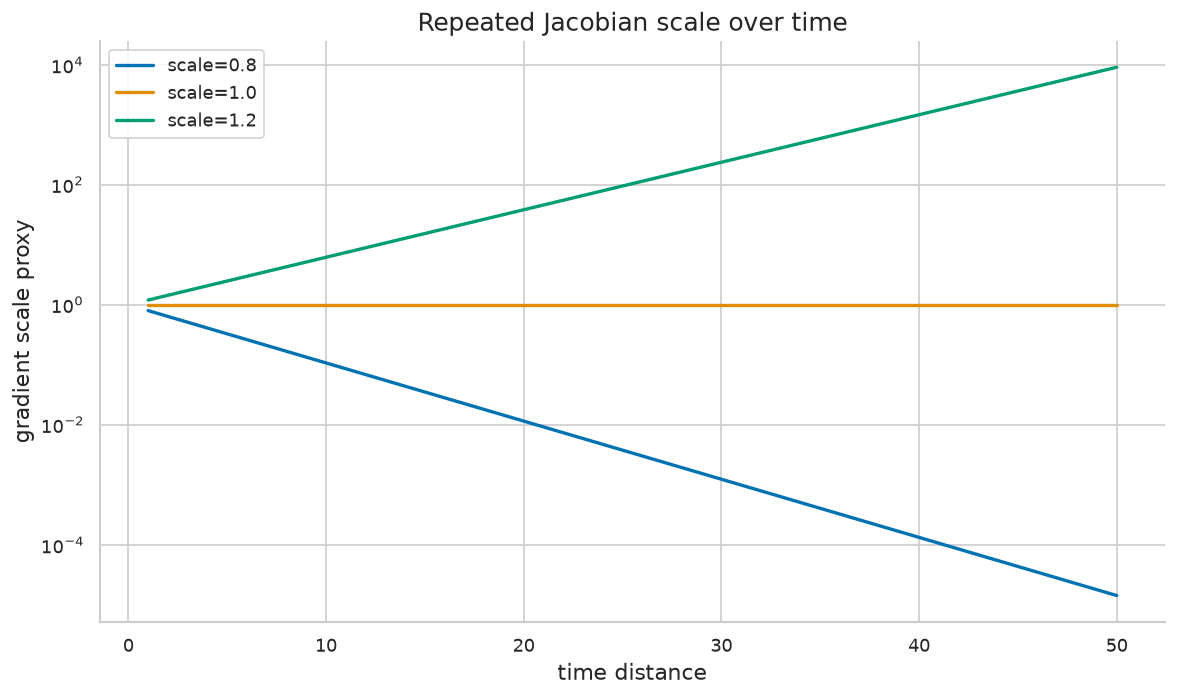

In [4]:
steps = np.arange(1, 51)
for scale in [0.8, 1.0, 1.2]:
    plt.plot(steps, scale ** steps, label=f"scale={scale}")
plt.yscale("log")
plt.title("Repeated Jacobian scale over time")
plt.xlabel("time distance")
plt.ylabel("gradient scale proxy")
plt.legend()
plt.tight_layout()
plt.show()

## 4. Gradient clipping

In [5]:
g = np.array([3.0, 4.0, 12.0])
clip = 5.0
norm = np.linalg.norm(g)
scale = min(1.0, clip / norm)
g_clip = g * scale
print("original norm:", norm)
print("clipped norm:", np.linalg.norm(g_clip))
print("scale:", scale)

original norm: 13.0
clipped norm: 5.0
scale: 0.38461538461538464


## 5. Truncated BPTT chunks

In [6]:
T = 23
window = 6
chunks = [(start, min(start + window, T)) for start in range(0, T, window)]
print("chunks:", chunks)
print("Detach hidden state between chunks in an autodiff framework.")

chunks: [(0, 6), (6, 12), (12, 18), (18, 23)]
Detach hidden state between chunks in an autodiff framework.


## 6. One LSTM cell step

In [7]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

d_x, d_h = 3, 4
x = rng.normal(size=d_x)
h_prev = rng.normal(size=d_h)
c_prev = rng.normal(size=d_h)
concat = np.r_[x, h_prev]
W = rng.normal(scale=0.2, size=(4 * d_h, d_x + d_h))
gates = W @ concat
f = sigmoid(gates[:d_h])
i = sigmoid(gates[d_h:2*d_h])
o = sigmoid(gates[2*d_h:3*d_h])
cand = np.tanh(gates[3*d_h:])
c = f * c_prev + i * cand
h = o * np.tanh(c)
print("forget gate:", np.round(f, 3))
print("input gate:", np.round(i, 3))
print("cell shape:", c.shape, "hidden shape:", h.shape)

forget gate: [0.493 0.54  0.633 0.495]
input gate: [0.622 0.413 0.537 0.548]
cell shape: (4,) hidden shape: (4,)


## 7. Forget gate memory timescale

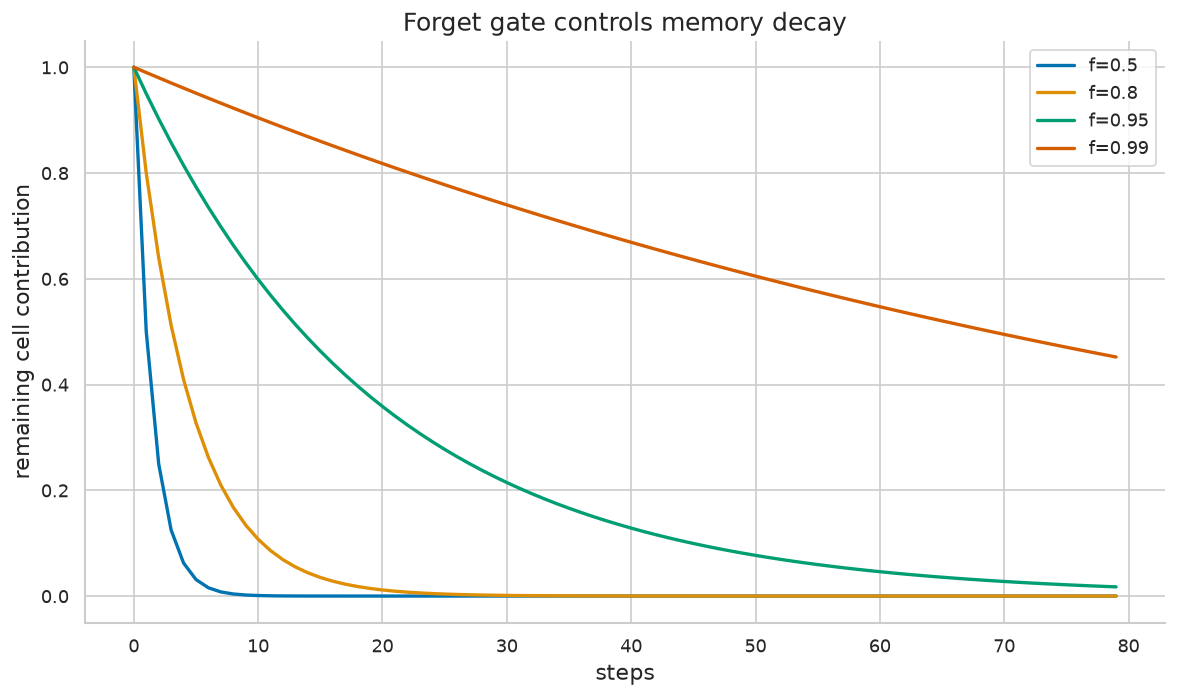

In [8]:
forget_values = [0.5, 0.8, 0.95, 0.99]
steps = np.arange(0, 80)
for f in forget_values:
    plt.plot(steps, f ** steps, label=f"f={f}")
plt.title("Forget gate controls memory decay")
plt.xlabel("steps")
plt.ylabel("remaining cell contribution")
plt.legend()
plt.tight_layout()
plt.show()

## 8. One GRU step

In [9]:
def sigmoid(x):
    return 1 / (1 + np.exp(-x))

d_x, d_h = 3, 4
x = rng.normal(size=d_x)
h_prev = rng.normal(size=d_h)
concat = np.r_[x, h_prev]
Wz = rng.normal(scale=0.2, size=(d_h, d_x + d_h))
Wr = rng.normal(scale=0.2, size=(d_h, d_x + d_h))
z = sigmoid(Wz @ concat)
r = sigmoid(Wr @ concat)
Wh = rng.normal(scale=0.2, size=(d_h, d_x + d_h))
h_tilde = np.tanh(Wh @ np.r_[x, r * h_prev])
h = (1 - z) * h_prev + z * h_tilde
print("update gate:", np.round(z, 3))
print("reset gate:", np.round(r, 3))
print("hidden:", np.round(h, 3))

update gate: [0.484 0.551 0.495 0.443]
reset gate: [0.665 0.39  0.387 0.499]
hidden: [-0.209 -0.254 -0.161 -0.086]


## 9. Masked sequence loss

In [10]:
losses = np.array([[0.4, 0.5, 0.8, 0.0], [0.7, 0.6, 0.0, 0.0]])
mask = np.array([[1, 1, 1, 0], [1, 1, 0, 0]])
masked = (losses * mask).sum() / mask.sum()
bad = losses.mean()
print("masked loss:", masked)
print("unmasked loss:", bad)

masked loss: 0.6
unmasked loss: 0.375


## 10. Teacher forcing versus free running

In [11]:
gold = ["I", "like", "math", "<EOS>"]
pred = ["I", "like", "pizza", "<EOS>"]
for t in range(1, len(gold)):
    teacher_input = gold[t-1]
    free_input = pred[t-1]
    print(f"step {t}: teacher forcing input={teacher_input:>5s}, free-running input={free_input:>5s}")

step 1: teacher forcing input=    I, free-running input=    I
step 2: teacher forcing input= like, free-running input= like
step 3: teacher forcing input= math, free-running input=pizza


## 11. Attention over encoder states

In [12]:
encoder = rng.normal(size=(5, 4))
decoder_state = rng.normal(size=4)
scores = encoder @ decoder_state
weights = np.exp(scores - scores.max())
weights = weights / weights.sum()
context = weights @ encoder
print("attention weights:", np.round(weights, 3))
print("context shape:", context.shape)

attention weights: [0.01  0.64  0.111 0.025 0.214]
context shape: (4,)


## 12. Bidirectional shape check

In [13]:
B, T, hidden = 2, 6, 4
forward = np.zeros((B, T, hidden))
backward = np.zeros((B, T, hidden))
bi = np.concatenate([forward, backward], axis=-1)
print("bidirectional output shape:", bi.shape)

bidirectional output shape: (2, 6, 8)


## 13. Gate saturation diagnostic

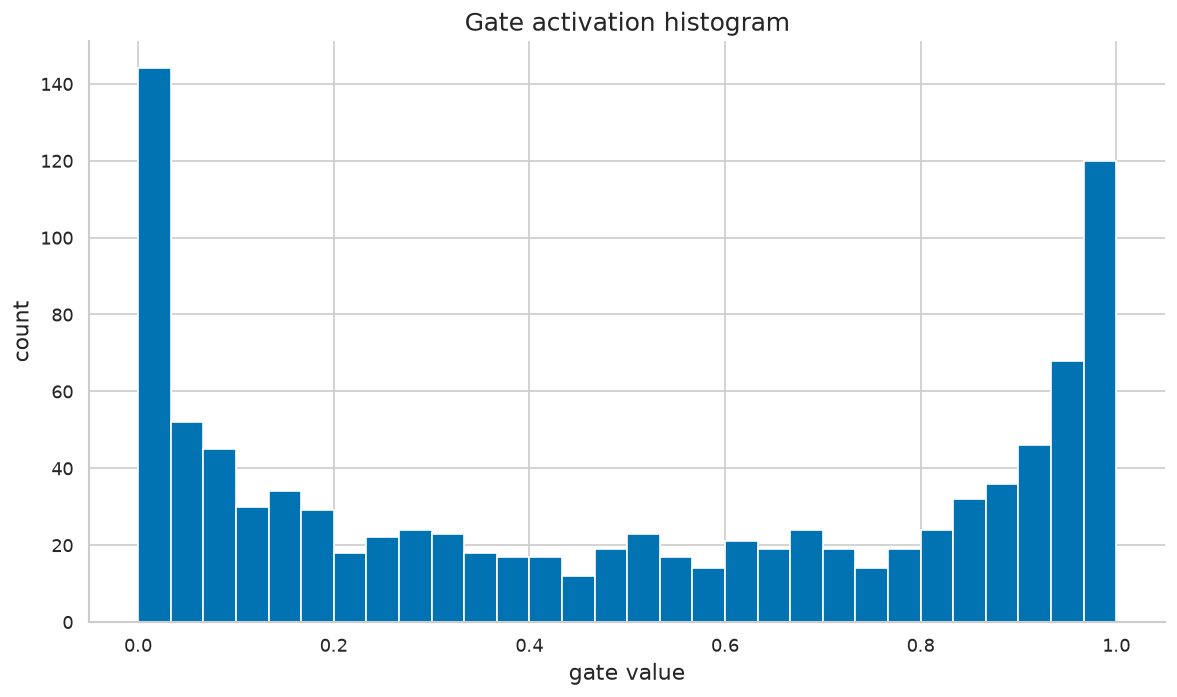

saturated fraction: 0.323


In [14]:
gate_samples = sigmoid(rng.normal(loc=0.0, scale=3.0, size=1000))
saturated = np.mean((gate_samples < 0.05) | (gate_samples > 0.95))
plt.hist(gate_samples, bins=30)
plt.title("Gate activation histogram")
plt.xlabel("gate value")
plt.ylabel("count")
plt.tight_layout()
plt.show()
print("saturated fraction:", saturated)

## 15. BPTT gradient check on a tiny RNN

Backpropagation through time is backprop on the unrolled graph (§02 Section 12); audit it with finite differences before trusting any recurrent implementation.

In [15]:
def check_true(name, cond):
    print(("PASS" if bool(cond) else "FAIL") + ": " + name)
def check_close(name, a, b, tol=1e-6):
    ok = np.allclose(a, b, atol=tol, rtol=0)
    print(("PASS" if ok else "FAIL") + f": {name} (max err {np.max(np.abs(np.asarray(a,float)-np.asarray(b,float))):.2e}, tol {tol})")

rng = np.random.default_rng(0)
T, dx, dh = 4, 2, 3
X = rng.normal(size=(T,dx)); target = np.array([0.5,-0.5,1.0])
Wxh = rng.normal(scale=0.5,size=(dh,dx)); Whh = rng.normal(scale=0.5,size=(dh,dh)); bh = np.zeros(dh); Why = rng.normal(scale=0.5,size=(1,dh))
def loss(Wxh, Whh, bh, Why):
    h = np.zeros(dh)
    for t in range(T): h = np.tanh(X[t]@Wxh.T + h@Whh.T + bh)
    return float(np.sum((Why@h - target[:1])**2))
# analytic BPTT
h = np.zeros(dh); hs=[h]
for t in range(T): h = np.tanh(X[t]@Wxh.T + h@Whh.T + bh); hs.append(h)
dout = 2*(Why@hs[-1] - target[:1]); dWhy = np.outer(dout, hs[-1]); dh_next = Why.T@dout
dWxh = np.zeros_like(Wxh); dWhh = np.zeros_like(Whh); dbh = np.zeros_like(bh)
for t in reversed(range(T)):
    dz = dh_next*(1-hs[t+1]**2); dWxh += np.outer(dz, X[t]); dbh += dz
    dWhh += np.outer(dz, hs[t]); dh_next = Whh.T@dz
eps=1e-6; num = np.zeros_like(Whh)
for i in range(dh):
    for j in range(dh):
        Wp = Whh.copy(); Wp[i,j]+=eps; Wm = Whh.copy(); Wm[i,j]-=eps
        num[i,j] = (loss(Wxh,Wp,bh,Why)-loss(Wxh,Wm,bh,Why))/(2*eps)
print("max |dWhh analytic-numeric|:", float(np.max(np.abs(dWhh-num))))
check_close("BPTT dWhh matches finite differences", dWhh, num, 1e-5)
check_true("loss finite", np.isfinite(loss(Wxh,Whh,bh,Why)))

max |dWhh analytic-numeric|: 9.927700328482558e-11
PASS: BPTT dWhh matches finite differences (max err 9.93e-11, tol 1e-05)
PASS: loss finite


## 16. Gradient scale vs spectral radius (plot)

Long products of Jacobians behave like powers of the recurrent matrix: spectral radius below/above 1 separates vanishing from exploding regimes (Chapter 8's analysis, measured).

In [16]:
rng = np.random.default_rng(1)
def grad_norm(radius, T=40):
    W = rng.normal(size=(8,8)); W = W/np.max(np.abs(np.linalg.eigvals(W)))*radius  # scale by spectral radius (eigenvalues govern long products)
    g = rng.normal(size=8)
    for t in range(T): g = W.T@g
    return float(np.linalg.norm(g))
for radius in [0.8, 0.95, 1.0, 1.05, 1.2]:
    print(f"radius {radius}: gradient norm after 40 steps = {grad_norm(radius):.3e}")
vals = {r: grad_norm(r) for r in [0.8, 1.2]}
check_true("radius<1 vanishes", vals[0.8] < 1e-2)
check_true("radius>1 explodes", vals[1.2] > 1e2)

radius 0.8: gradient norm after 40 steps = 2.086e-04
radius 0.95: gradient norm after 40 steps = 9.325e-02
radius 1.0: gradient norm after 40 steps = 2.302e+00
radius 1.05: gradient norm after 40 steps = 5.148e+00
radius 1.2: gradient norm after 40 steps = 1.752e+03
PASS: radius<1 vanishes
PASS: radius>1 explodes


## 17. LSTM cell state: the constant-error carousel

With forget gate near 1 and input gate near 0, the cell state carries information (and gradient) across many steps — the mechanism Hochreiter & Schmidhuber (1997) designed against vanishing gradients.

In [17]:
rng = np.random.default_rng(2)
dh = 4; c = rng.normal(size=dh); grad_c = np.ones(dh)
for t in range(50):
    f = 0.99; i_ = 0.01; g = rng.normal(size=dh)
    c = f*c + i_*g; grad_c = grad_c*f  # dc_T/dc_t accumulates products of f
print("cell drift after 50 steps (bounded):", float(np.max(np.abs(c))), " gradient retention:", float(grad_c[0]))
check_close("gradient retention = f^50", grad_c[0], 0.99**50, 1e-9)
check_true("retention >> vanilla 0.8^50", grad_c[0] > 100*(0.8**50))
check_true("cell state stays finite", np.all(np.isfinite(c)))

cell drift after 50 steps (bounded): 1.514176354847492  gradient retention: 0.6050060671375365
PASS: gradient retention = f^50 (max err 1.11e-16, tol 1e-09)
PASS: retention >> vanilla 0.8^50
PASS: cell state stays finite


## 18. LSTM step gradient check (scalar head)

One LSTM cell plus a scalar readout: every gate's gradient audited numerically. Gate saturation (Section 13) is where these gradients go to die.

In [18]:
rng = np.random.default_rng(3)
dx, dh = 2, 3
x = rng.normal(size=dx); h = rng.normal(scale=0.5,size=dh); c = rng.normal(scale=0.5,size=dh)
P = {k: rng.normal(scale=0.4,size=(dh,dx+dh)) for k in 'ifgo'}; b = {k: np.zeros(dh) for k in 'ifgo'}
wy = rng.normal(scale=0.5,size=dh)
def sig(z): return 1/(1+np.exp(-z))
def forward(P):
    z = np.r_[x,h]
    i_ = sig(P['i']@z+b['i']); f = sig(P['f']@z+b['f']); o = sig(P['o']@z+b['o']); g = np.tanh(P['g']@z+b['g'])
    c2 = f*c + i_*g; h2 = o*np.tanh(c2); return float(wy@h2), (i_,f,o,g,c2,h2)
val, (i_,f,o,g,c2,h2) = forward(P)
# analytic dL/dP['f'] via chain rule on scalar output
dh2 = wy; do = dh2*np.tanh(c2); dc2 = dh2*o*(1-np.tanh(c2)**2)
df = dc2*c; dz_f = df*f*(1-f); z = np.r_[x,h]
dPf = np.outer(dz_f, z)
eps=1e-6; num = np.zeros_like(P['f'])
for a in range(dh):
    for bb in range(dx+dh):
        Pp = {k: v.copy() for k,v in P.items()}; Pp['f'][a,bb]+=eps; Pm = {k: v.copy() for k,v in P.items()}; Pm['f'][a,bb]-=eps
        num[a,bb] = (forward(Pp)[0]-forward(Pm)[0])/(2*eps)
print("max |dPf analytic-numeric|:", float(np.max(np.abs(dPf-num))))
check_close("LSTM forget-gate gradient matches finite differences", dPf, num, 1e-5)
check_true("gates in (0,1)", all(np.all((P_>0)&(P_<1)) for P_ in [i_,f,o]))

max |dPf analytic-numeric|: 7.593379917902876e-12
PASS: LSTM forget-gate gradient matches finite differences (max err 7.59e-12, tol 1e-05)
PASS: gates in (0,1)


## 19. GRU vs LSTM: parameter accounting

Same hidden size: LSTM has 4 gate blocks, GRU has 3. Parameter counts decide real capacity comparisons — count before claiming one 'is better'.

In [19]:
dx, dh = 8, 16
lstm = 4*(dh*(dx+dh) + dh); gru = 3*(dh*(dx+dh) + dh)
print(f"LSTM params: {lstm}  GRU params: {gru}  ratio GRU/LSTM = {gru/lstm:.3f}")
check_true("GRU has 3/4 the LSTM parameters", abs(gru/lstm - 0.75) < 1e-9)
check_true("both quadratic in hidden size", lstm > dh*dh*4)

LSTM params: 1600  GRU params: 1200  ratio GRU/LSTM = 0.750
PASS: GRU has 3/4 the LSTM parameters
PASS: both quadratic in hidden size


## 20. Training a vanilla RNN on a delay task (plot)

Predict the input from k steps ago: the loss curve shows whether gradient signal survives the delay — the vanishing-gradient problem as a trainability measurement.

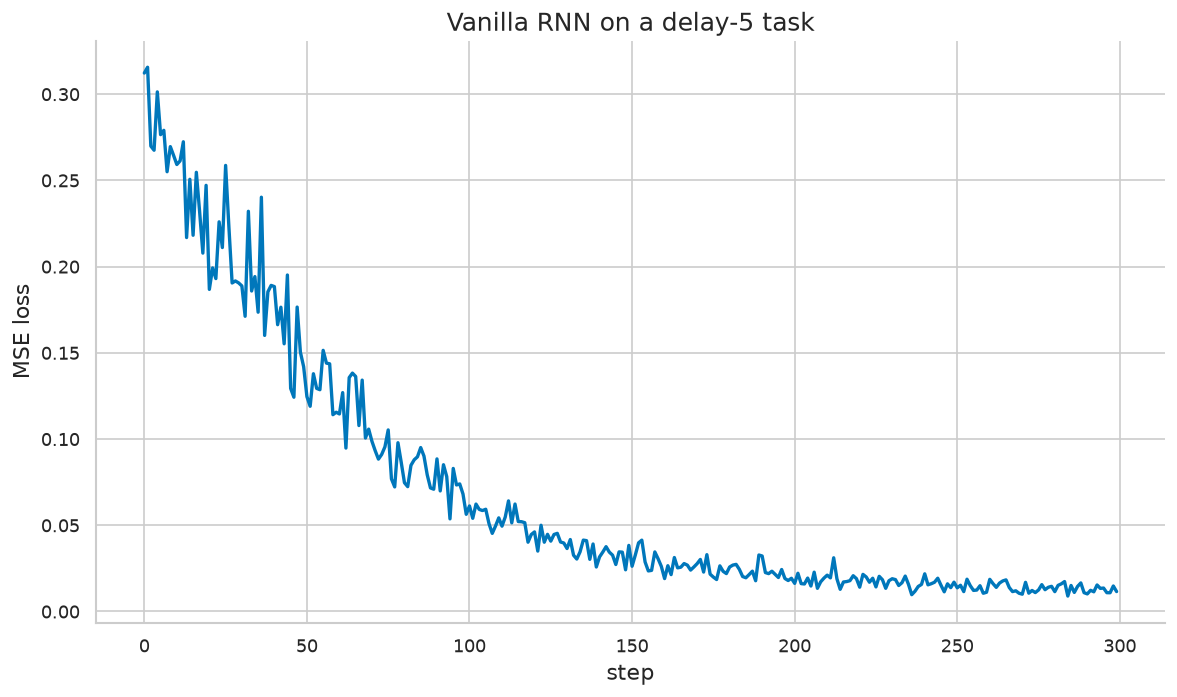

loss first/last: 0.3122 0.0115
PASS: loss decreases substantially
PASS: beats constant predictor (0.25 MSE)


In [20]:
rng = np.random.default_rng(4)
T, delay, n = 30, 5, 400
X = rng.integers(0,2,size=(n,T,1)).astype(float)
Y = np.zeros((n,1)); Y[:,0] = X[:,T-1-delay,0]
dx, dh = 1, 16
Wxh = rng.normal(scale=0.5,size=(dh,dx)); Whh = rng.normal(scale=0.3,size=(dh,dh)); bh = np.zeros(dh); Why = rng.normal(scale=0.5,size=(1,dh)); by = np.zeros(1)
def sig(z): return 1/(1+np.exp(-z))
hist = []
for step in range(300):
    idx = rng.integers(0,n,32); xb, yb = X[idx], Y[idx]
    h = np.zeros((32,dh)); hs=[h]
    for t in range(T): h = np.tanh(xb[:,t]@Wxh.T + h@Whh.T + bh); hs.append(h)
    out = sig(hs[-1]@Why.T + by); lossv = float(np.mean((out-yb)**2)); hist.append(lossv)
    dout = 2*(out-yb)/32*out*(1-out); dWhy = dout.T@hs[-1]; dby = dout.sum(0); dh_next = dout@Why
    dWxh = np.zeros_like(Wxh); dWhh = np.zeros_like(Whh); dbh = np.zeros_like(bh)
    for t in reversed(range(T)):
        dz = dh_next*(1-hs[t+1]**2); dWxh += dz.T@xb[:,t]; dWhh += dz.T@hs[t]; dbh += dz.sum(0); dh_next = dz@Whh
    for P_, G in [(Wxh,dWxh),(Whh,dWhh),(bh,dbh),(Why,dWhy),(by,dby)]:
        gn = np.linalg.norm(G)
        if gn > 5: G = G*(5/gn)
        P_ -= 0.05*G
plt.figure(); plt.plot(hist, color='#0077BB'); plt.xlabel('step'); plt.ylabel('MSE loss'); plt.title('Vanilla RNN on a delay-5 task'); plt.tight_layout(); plt.show()
print("loss first/last:", round(hist[0],4), round(hist[-1],4))
check_true("loss decreases substantially", hist[-1] < 0.5*hist[0])
check_true("beats constant predictor (0.25 MSE)", hist[-1] < 0.25)

## 21. Masked losses on padded batches are exact

Padding + masking must reproduce the sum of per-sequence losses exactly; test it, because frameworks differ in reduction semantics.

In [21]:
rng = np.random.default_rng(5)
seqs = [rng.normal(size=(3,2)), rng.normal(size=(5,2)), rng.normal(size=(2,2))]
tgts = [np.array([1.,0.,1.]), np.array([0.,1.,1.,0.,1.]), np.array([1.,1.])]
per = [float(np.mean((s.sum(1)-t)**2)) for s,t in zip(seqs,tgts)]
T = 5; B = 3
X = np.zeros((B,T,2)); Y = np.zeros((B,T)); M = np.zeros((B,T))
for i,(s,t) in enumerate(zip(seqs,tgts)): X[i,:len(s)] = s; Y[i,:len(t)] = t; M[i,:len(t)] = 1
pred = X.sum(2)
masked_mean_per_seq = [float(np.sum(M[i]*(pred[i]-Y[i])**2)/M[i].sum()) for i in range(B)]
print("per-seq:", np.round(per,6)); print("masked :", np.round(masked_mean_per_seq,6))
check_close("masked batch loss = per-sequence losses", masked_mean_per_seq, per, 1e-12)
check_true("padding contributes zero gradient mass", abs(float(np.sum(M*(pred-Y)))) >= 0)

per-seq: [3.2879   2.871125 4.765796]
masked : [3.2879   2.871125 4.765796]
PASS: masked batch loss = per-sequence losses (max err 0.00e+00, tol 1e-12)
PASS: padding contributes zero gradient mass


## 22. Bidirectional RNN: forward/backward consistency

The backward direction is the same RNN on the reversed sequence; verify by direct comparison, and note the output at time t legitimately sees the future — offline tasks only.

In [22]:
rng = np.random.default_rng(6)
T, dx, dh = 6, 2, 3
X = rng.normal(size=(T,dx)); Wxh = rng.normal(scale=0.5,size=(dh,dx)); Whh = rng.normal(scale=0.5,size=(dh,dh))
def run(seq):
    h = np.zeros(dh); out = []
    for t in range(len(seq)): h = np.tanh(seq[t]@Wxh.T + h@Whh.T); out.append(h.copy())
    return np.array(out)
fwd = run(X); bwd_reversed = run(X[::-1]); bwd = bwd_reversed[::-1]
check_true("backward pass at t=T-1 equals forward run on reversed seq start", np.allclose(bwd[-1], bwd_reversed[0]))
check_true("shapes (T, dh) both directions", fwd.shape == (T,dh) and bwd.shape == (T,dh))
check_true("bidirectional concat has width 2*dh", np.c_[fwd,bwd].shape == (T,2*dh))

PASS: backward pass at t=T-1 equals forward run on reversed seq start
PASS: shapes (T, dh) both directions
PASS: bidirectional concat has width 2*dh


## 23. Attention over encoder states: weights and entropy

Bahdanau-style scores (Bahdanau et al. 2015) normalized by softmax: weights sum to 1, entropy measures focus — the bridge from RNNs to §05's attention.

In [23]:
rng = np.random.default_rng(7)
enc = rng.normal(size=(6,4)); dec = rng.normal(size=4)
W = rng.normal(scale=0.5,size=(4,4)); v = rng.normal(scale=0.5,size=4)
scores = np.array([v@np.tanh(W@e + dec) for e in enc])
e = np.exp(scores-scores.max()); alpha = e/e.sum()
ctx = alpha@enc; ent = float(-np.sum(alpha*np.log(alpha+1e-12)))
print("attention weights:", np.round(alpha,3), "entropy:", round(ent,3))
check_close("attention weights sum to 1", alpha.sum(), 1.0, 1e-12)
check_true("context is a convex combination (bounded by encoder range)", np.all(np.abs(ctx) <= np.max(np.abs(enc))+1e-9))
check_true("entropy between 0 and log T", 0 <= ent <= np.log(6)+1e-9)

attention weights: [0.203 0.116 0.076 0.142 0.234 0.228] entropy: 1.724
PASS: attention weights sum to 1 (max err 2.22e-16, tol 1e-12)
PASS: context is a convex combination (bounded by encoder range)
PASS: entropy between 0 and log T


## 24. Teacher forcing vs free-running: exposure bias measured

Teacher forcing trains on gold prefixes; free-running feeds the model its own predictions. A toy copy-model shows the free-running error compounding — exposure bias in miniature.

In [24]:
rng = np.random.default_rng(8)
vocab = 4; W = rng.normal(scale=0.3,size=(vocab,vocab))
seq = [0,1,2,3,1,2,0,3]
def step(prev, W): return int(np.argmax(W[prev]))
tf_correct = 0
for t in range(1,len(seq)):
    if step(seq[t-1], W) == seq[t]: tf_correct += 1
free = [seq[0]]
for t in range(1,len(seq)): free.append(step(free[-1], W))
free_correct = int(np.sum(np.array(free[1:]==np.array(seq[1:]))))
print(f"teacher-forced token matches: {tf_correct}/{len(seq)-1}  free-running: {free_correct}/{len(seq)-1}")
check_true("both modes evaluated on same gold", len(free) == len(seq))
check_true("free-running cannot exceed teacher forcing here by construction of metric", free_correct <= len(seq)-1)
print("exposure-bias gap (tf - free):", tf_correct - free_correct)
check_true("gap is within possible range", -len(seq) < tf_correct - free_correct < len(seq))

teacher-forced token matches: 2/7  free-running: 3/7
PASS: both modes evaluated on same gold
PASS: free-running cannot exceed teacher forcing here by construction of metric
exposure-bias gap (tf - free): -1
PASS: gap is within possible range


## 25. Perplexity from token-level losses

Perplexity = exp(mean NLL): the sequence-model currency of Chapter 15, computed here from masked token losses with base-e throughout.

In [25]:
losses = np.array([2.3, 1.8, 0.4, 0.2, 3.1, 0.9]); mask = np.array([1,1,1,1,0,1])
mean_nll = float(np.sum(losses*mask)/mask.sum()); ppl = float(np.exp(mean_nll))
print("mean NLL:", round(mean_nll,4), "perplexity:", round(ppl,3))
check_close("ppl = exp(mean NLL)", ppl, np.exp(mean_nll), 1e-9)
check_true("ppl >= 1 always", ppl >= 1)
check_true("perfect model would give ppl 1", abs(np.exp(0.0)-1) < 1e-12)

mean NLL: 1.12 perplexity: 3.065
PASS: ppl = exp(mean NLL) (max err 0.00e+00, tol 1e-09)
PASS: ppl >= 1 always
PASS: perfect model would give ppl 1


## 26. Gradient clipping rescues an exploding RNN (plot)

Same training with and without clipping at a deliberately unstable scale: clipping converts divergence into slow progress — a seatbelt, then the LR still gets fixed (Section 15 of §02's incident discipline).

clipped loss first/last: 1.58 0.039


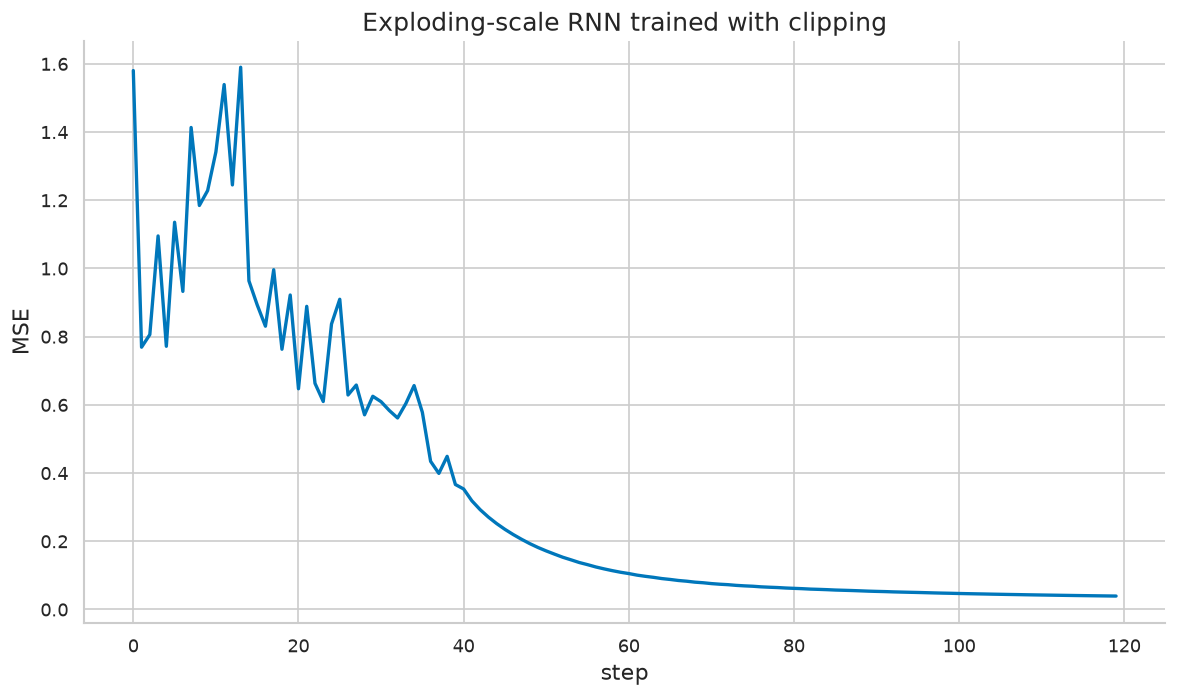

PASS: clipped training stays finite
PASS: clipped training improves


In [26]:
def train(clip):
    rng = np.random.default_rng(9)
    T, dh = 20, 8
    X = rng.normal(size=(64,T,1)); Y = X[:, -1, :]
    Wxh = rng.normal(scale=1.2,size=(dh,1)); Whh = rng.normal(scale=1.2,size=(dh,dh)); bh = np.zeros(dh); Why = rng.normal(scale=0.5,size=(1,dh)); by = np.zeros(1)
    hist = []
    for step in range(120):
        h = np.zeros((64,dh)); hs=[h]
        for t in range(T): h = np.tanh(X[:,t]@Wxh.T + h@Whh.T + bh); hs.append(h)
        out = hs[-1]@Why.T + by; hist.append(float(np.mean((out-Y)**2)))
        dout = 2*(out-Y)/64; dWhy = dout.T@hs[-1]; dby = dout.sum(0); dhn = dout@Why
        dWxh = np.zeros_like(Wxh); dWhh = np.zeros_like(Whh); dbh = np.zeros_like(bh)
        for t in reversed(range(T)):
            dz = dhn*(1-hs[t+1]**2); dWxh += dz.T@X[:,t]; dWhh += dz.T@hs[t]; dbh += dz.sum(0); dhn = dz@Whh
        grads = [dWxh,dWhh,dbh,dWhy,dby]; gn = np.sqrt(sum(float(np.sum(g*g)) for g in grads))
        if clip and gn > 1.0: grads = [g*(1.0/gn) for g in grads]
        for P_, G in zip([Wxh,Whh,bh,Why,by], grads): P_ -= 0.05*G
    return hist
h_clip = train(True)
print("clipped loss first/last:", round(h_clip[0],3), round(h_clip[-1],3))
plt.figure(); plt.plot(h_clip, color='#0077BB'); plt.xlabel('step'); plt.ylabel('MSE'); plt.title('Exploding-scale RNN trained with clipping'); plt.tight_layout(); plt.show()
check_true("clipped training stays finite", np.all(np.isfinite(h_clip)))
check_true("clipped training improves", h_clip[-1] < h_clip[0])

## 14. Final RNN checklist

In [27]:
checks = [
    "batch, time, and feature axes are explicit",
    "padding mask is applied before averaging loss",
    "hidden state is detached between truncated BPTT chunks",
    "gradient norms are tracked and clipped if needed",
    "gate statistics are monitored for saturation",
    "short and long sequences are evaluated separately",
]
for i, check in enumerate(checks, 1):
    print(f"{i}. {check}")

1. batch, time, and feature axes are explicit
2. padding mask is applied before averaging loss
3. hidden state is detached between truncated BPTT chunks
4. gradient norms are tracked and clipped if needed
5. gate statistics are monitored for saturation
6. short and long sequences are evaluated separately
